# Imports

In [1]:
import torch 
import torch.nn as nn
import math
import typing
from typing import List, Union
import pandas as pd
import torch.nn.functional as F
import numpy as np
from datetime import datetime
import matplotlib.pyplot as plt
from torch.utils.data import Dataset

from torch.utils.data import DataLoader
import random
import seaborn as sns

from torch.nn.utils.rnn import pad_sequence
import torch
from torch.utils.data import Dataset
import random
import torch
import torch.nn as nn
import math
import matplotlib.pyplot as plt
import pandas as pd
import os
from PIL import Image
import glob

In [2]:
import os
os.environ["CUDA_LAUNCH_BLOCKING"] = "1"

# Dataset

In [3]:
df = pd.read_parquet(r'bert_trainset_squared_25.gzip')
print(df.shape)
df.head(2)

(15643, 11)


,t,pos,distance_travelled,vel,rot_vel,head_direction,position_state,position_state_id,normalized_position_state_id,last_position_state_id,change_of_position_state
0,0.15,"[0.116, 0.05]",0.015121,"[0.09702576630862492, 0.07825506978033414]",-1.014355,"[0.8540567915661367, 0.5201797735204211]",COQVSOAUMTUPMTASCRFN,257,0.268828,256.0,1
1,0.45,"[0.143, 0.092]",0.064938,"[0.10024711755413862, 0.1422307007613116]",-0.841585,"[0.5717389806063935, 0.8204355782480194]",SOAUCOQVMTUPMTASCRFN,789,0.825314,257.0,1


In [4]:
token_to_ps = {pid:ps for pid, ps in zip(df['position_state_id'], df['position_state'])}
ps_to_token = {ps:pid for pid, ps in zip(df['position_state_id'], df['position_state'])}

In [5]:
df['position_state_id'].nunique()

954

In [6]:
df['apd_position_state_id'] = [val for val in df['position_state_id']]

In [7]:
df['position_state_id'] = df.groupby('apd_position_state_id').transform('ngroup')

In [8]:
apd_to_df_ps_id = {k:v for k, v in zip(df['apd_position_state_id'], df['position_state_id'])}
df_to_apd_ps_id = {v:k for k, v in zip(df['apd_position_state_id'], df['position_state_id'])}

In [9]:
df['position_state_id'].describe()

count    15643.000000
mean       471.705236
std        273.779721
min          0.000000
25%        236.000000
50%        466.000000
75%        706.500000
max        953.000000
Name: position_state_id, dtype: float64

<Axes: xlabel='position_state_id', ylabel='Count'>

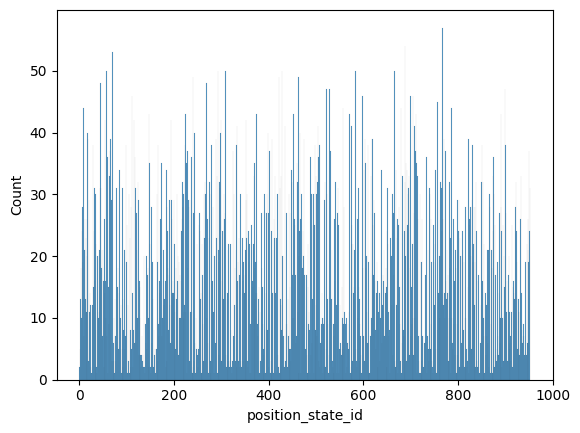

In [10]:
sns.histplot(df, x='position_state_id', binwidth=1)#.value_counts(normalize=True).hist(grid=False, )

<Axes: >

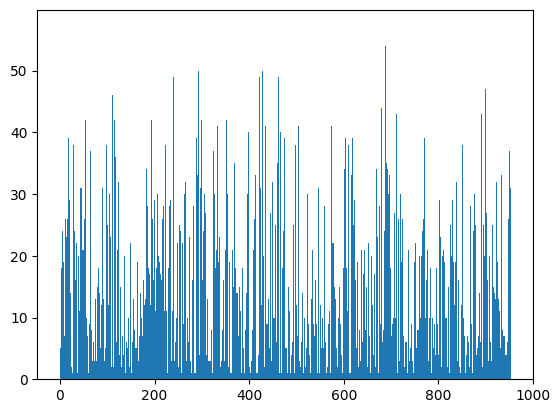

In [11]:
df['position_state_id'].hist(grid=False, bins=range(df['position_state_id'].nunique()))

## tokenized dataset

In [12]:
df['position_state_id'].head()

0    224
1    704
2    711
3    598
4    609
Name: position_state_id, dtype: int64

# Classes

In [13]:
from torch.nn.utils.rnn import pad_sequence

def collate_masked_batch(batch, pad_token_id=0):
    xs, ys = zip(*batch)
    x = pad_sequence(xs, batch_first=True, padding_value=pad_token_id)
    y = pad_sequence(ys, batch_first=True, padding_value=-100)
    # attention_mask: 1 onde não é PAD
    attention_mask = (x != pad_token_id).long()
    return x, y, attention_mask

### dataset class

In [45]:
# [Célula] Dataset com limites de tamanho de trecho (3..9, por ex.)
class TrajectoryMaskingDataset(Dataset):
    def __init__(
        self,
        full_sequence,
        mask_token_id,
        min_len=3,
        max_len=15,
        mask_frac=0.30,          # fração média dos tokens internos a mascarar
        min_span_len=3,          # <-- novo: tamanho mínimo do trecho
        max_span_len=9,          # <-- novo: tamanho máximo do trecho
        use_bert_801010=False,   # opcional
        vocab_size=None,         # opcional, para 80/10/10
        bos_token_id=None,
        eos_token_id=None,
    ):
        assert 1 <= min_span_len <= max_span_len, "faixa de span inconsistente"
        self.full_sequence = list(full_sequence)
        if bos_token_id is not None:
            self.full_sequence = [bos_token_id] + self.full_sequence
        if eos_token_id is not None:
            self.full_sequence = self.full_sequence + [eos_token_id]

        self.mask_token_id = mask_token_id
        self.min_len = min_len
        self.max_len = max_len
        self.mask_frac = mask_frac
        self.min_span_len = min_span_len
        self.max_span_len = max_span_len
        self.use_bert_801010 = use_bert_801010
        self.vocab_size = vocab_size
        self.bos_token_id = bos_token_id
        self.eos_token_id = eos_token_id

        # janelas possíveis
        self.start_indices = list(range(0, max(1, len(self.full_sequence) - self.min_len)))

    def __len__(self):
        return len(self.start_indices)

    def _sample_spans(self, L):
        """
        Amostra spans contíguos dentro de [1, L-2] (não toca 0 nem L-1),
        com tamanhos entre [min_span_len, max_span_len], sem ultrapassar os limites.
        Garante pelo menos 1 span quando houver espaço.
        Retorna um conjunto de índices a mascarar.
        """
        inner = list(range(1, L - 1))
        if len(inner) == 0:
            return set()

        # alvo: quantos tokens internos queremos mascarar (por fração)
        target = max(self.min_span_len, int(round(self.mask_frac * len(inner))))
        masked = set()
        guard = 0

        # mapa de posições livres para evitar sobreposição excessiva
        free = [True] * L
        free[0] = free[L - 1] = False  # nunca mascarar bordas

        def try_place_span():
            # escolhe um start livre
            candidates = [i for i in range(1, L - 1) if free[i]]
            if not candidates:
                return False
            start = random.choice(candidates)
            # escolhe comprimento dentro da faixa, mas respeitando L-1
            max_len_here = min(self.max_span_len, (L - 1) - start)
            if max_len_here < self.min_span_len:
                return False
            span_len = random.randint(self.min_span_len, max_len_here)

            # valida espaço livre [start, start+span_len)
            for j in range(start, start + span_len):
                if j >= L - 1 or not free[j]:
                    return False

            # aplica
            for j in range(start, start + span_len):
                masked.add(j)
                free[j] = False
            return True

        # tenta colocar spans até atingir próximo do alvo
        while len(masked) < target and guard < 10 * L:
            placed = try_place_span()
            guard += 1
            if not placed and len(masked) == 0:
                # fallback: relaxa e tenta permitir pequena sobreposição
                start = random.randint(1, max(1, L - 1 - self.min_span_len))
                span_len = min(self.max_span_len, (L - 1) - start)
                span_len = max(span_len, self.min_span_len)
                for j in range(start, min(L - 1, start + span_len)):
                    masked.add(j)
                break

        # garante pelo menos um span se houver espaço interno suficiente
        if len(masked) == 0 and (L - 2) >= self.min_span_len:
            start = random.randint(1, max(1, L - 1 - self.min_span_len))
            span_len = min(self.max_span_len, (L - 1) - start)
            span_len = max(span_len, self.min_span_len)
            for j in range(start, min(L - 1, start + span_len)):
                masked.add(j)

        return masked

    def __getitem__(self, idx):
        start = self.start_indices[idx]
        seq_len = random.randint(self.min_len, self.max_len)
        end = min(start + seq_len, len(self.full_sequence))
        seq = self.full_sequence[start:end]

        L = len(seq)
        input_ids = list(seq)
        target_ids = [-100] * L

        masked_positions = self._sample_spans(L)

        for j in sorted(masked_positions):
            target_ids[j] = seq[j]
            if self.use_bert_801010 and self.vocab_size is not None:
                r = random.random()
                if r < 0.8:
                    input_ids[j] = self.mask_token_id
                elif r < 0.9:
                    input_ids[j] = random.randrange(self.vocab_size)
                else:
                    input_ids[j] = seq[j]
            else:
                input_ids[j] = self.mask_token_id

        return torch.tensor(input_ids, dtype=torch.long), torch.tensor(target_ids, dtype=torch.long)


In [15]:
# [Célula] Modelo
class TrajectoryBERT(nn.Module):
    def __init__(
        self,
        vocab_size,
        embed_size,
        num_layers,
        num_heads,
        hidden_dim,
        dropout=0.1,
        max_len=512,
        pad_token_id=0,
    ):
        super().__init__()
        self.pad_token_id = pad_token_id
        self.max_len = max_len

        self.embedding = nn.Embedding(vocab_size, embed_size)
        self.position_embedding = nn.Embedding(max_len, embed_size)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_size,
            nhead=num_heads,
            dim_feedforward=hidden_dim,
            dropout=dropout,
            batch_first=True,
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.fc_out = nn.Linear(embed_size, vocab_size)

    def forward(self, x, attention_mask: torch.tensor = None):
        """
        x: [B, T] ids (com PAD e possivelmente [MASK])
        attention_mask (opcional): [B, T] onde 1=token válido, 0=PAD (estilo HF) ou bool invertida.
        Se None, usa (x == pad_token_id) internamente.
        """
        B, T = x.size()
        device = x.device

        # posições (corta a sequência se ultrapassar max_len)
        if T > self.max_len:
            x = x[:, : self.max_len]
            T = self.max_len
        pos = torch.arange(T, device=device).unsqueeze(0).expand(B, T)

        h = self.embedding(x) + self.position_embedding(pos)

        # Normalizar diferentes convenções de máscara:
        # - se vier None: usa padding mask a partir de x
        # - se vier float/int (1=keep, 0=pad): converte para bool ignorando PAD
        # - se vier bool já no formato do nn.Transformer (True=IGNORAR): usa direto
        if attention_mask is None:
            key_padding_mask = (x == self.pad_token_id)  # True=ignorar
        else:
            if attention_mask.dtype != torch.bool:
                # assume 1=token válido, 0=PAD
                key_padding_mask = (attention_mask == 0)
            else:
                # se já for bool, consideramos True=ignorar (caso já venha nesse formato)
                key_padding_mask = attention_mask

        h = self.encoder(h, src_key_padding_mask=key_padding_mask)
        logits = self.fc_out(h)  # [B, T, V]
        return logits


# Definitions

In [46]:
# Hiperparâmetros
embed_size = 256
num_layers = 2
num_heads = 2
hidden_dim = 512
mask_token_id = df['position_state_id'].max()
pad_token_id = df['position_state_id'].max() + 1
vocab_size = pad_token_id + 1
max_len = 10
dropout = 0.3
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
num_epochs = 30
# Simulando dados
sequences = df['position_state_id'].values

device, vocab_size

(device(type='cuda'), 955)

In [17]:
max_len

9

In [18]:
sequences

array([224, 704, 711, ..., 146, 148, 111])

In [19]:
# df['position_state_id'].describe()

In [20]:
mask_token_id, pad_token_id

(953, 954)

In [47]:
# [Célula] Dataset e dataloaders
dataset = TrajectoryMaskingDataset(sequences, mask_token_id, max_len=max_len, )

train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size
train_dataset, val_dataset = torch.utils.data.random_split(dataset, [train_size, val_size])

train_loader = DataLoader(
    train_dataset, batch_size=32, shuffle=True,
    collate_fn=lambda b: collate_masked_batch(b, pad_token_id)
)
val_loader = DataLoader(
    val_dataset, batch_size=32, shuffle=False,
    collate_fn=lambda b: collate_masked_batch(b, pad_token_id)
)

In [50]:
# [Célula] Inicialização do modelo
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = TrajectoryBERT(
    vocab_size,
    embed_size=embed_size,
    num_layers=num_layers,
    num_heads=num_heads,
    hidden_dim=hidden_dim,
    dropout=dropout,
    pad_token_id=pad_token_id,
    max_len=max_len,   # ajuste se necessário
).to(device)

In [51]:
# [Célula] Otimizador e critério
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
# per-token para conseguirmos média apenas nos alvos válidos (-100 é ignorado)
criterion = nn.CrossEntropyLoss(ignore_index=-100, reduction='none')

In [52]:
# [Célula] Loop de treinamento
train_losses, val_losses = [], []
train_perplexities, val_perplexities = [], []

for epoch in range(num_epochs):
    model.train()
    train_nll_sum = 0.0
    train_tok_count = 0

    for x, y, attn in train_loader:
        x, y, attn = x.to(device), y.to(device), attn.to(device)

        optimizer.zero_grad()
        # pode passar a máscara (agora suportada), mas não é obrigatório
        logits = model(x, attention_mask=attn)

        # perda por token e média apenas onde y != -100
        loss_vec = criterion(logits.view(-1, vocab_size), y.view(-1))  # [B*T]
        valid = (y.view(-1) != -100)
        loss = loss_vec[valid].mean()

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)  # opcional, ajuda na estabilidade
        optimizer.step()

        train_nll_sum += loss_vec[valid].sum().item()
        train_tok_count += valid.sum().item()

    # ---- validação ----
    model.eval()
    val_nll_sum = 0.0
    val_tok_count = 0
    with torch.no_grad():
        for x_val, y_val, attn_val in val_loader:
            x_val, y_val, attn_val = x_val.to(device), y_val.to(device), attn_val.to(device)
            val_logits = model(x_val, attention_mask=attn_val)

            v_loss_vec = criterion(val_logits.view(-1, vocab_size), y_val.view(-1))
            v_valid = (y_val.view(-1) != -100)
            val_nll_sum += v_loss_vec[v_valid].sum().item()
            val_tok_count += v_valid.sum().item()

    # perdas médias por token e perplexidade
    avg_train_loss = train_nll_sum / max(1, train_tok_count)
    avg_val_loss   = val_nll_sum   / max(1, val_tok_count)
    train_ppl = math.exp(avg_train_loss)
    val_ppl   = math.exp(avg_val_loss)

    train_losses.append(avg_train_loss);  val_losses.append(avg_val_loss)
    train_perplexities.append(train_ppl); val_perplexities.append(val_ppl)

    if (epoch + 1) % max(1, num_epochs // 10) == 0 or (epoch + 1) == num_epochs:
        print(
            f"Epoch {epoch+1}/{num_epochs} | "
            f"Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | "
            f"Train PPL: {train_ppl:.2f} | Val PPL: {val_ppl:.2f}"
        )


Epoch 3/30 | Train Loss: 6.0260 | Val Loss: 5.4509 | Train PPL: 414.06 | Val PPL: 232.97
Epoch 6/30 | Train Loss: 4.0974 | Val Loss: 3.5554 | Train PPL: 60.18 | Val PPL: 35.00
Epoch 9/30 | Train Loss: 3.2135 | Val Loss: 2.8831 | Train PPL: 24.87 | Val PPL: 17.87
Epoch 12/30 | Train Loss: 2.8003 | Val Loss: 2.5112 | Train PPL: 16.45 | Val PPL: 12.32
Epoch 15/30 | Train Loss: 2.5508 | Val Loss: 2.3080 | Train PPL: 12.82 | Val PPL: 10.05
Epoch 18/30 | Train Loss: 2.3936 | Val Loss: 2.1314 | Train PPL: 10.95 | Val PPL: 8.43
Epoch 21/30 | Train Loss: 2.2600 | Val Loss: 2.0252 | Train PPL: 9.58 | Val PPL: 7.58
Epoch 24/30 | Train Loss: 2.1890 | Val Loss: 1.9509 | Train PPL: 8.93 | Val PPL: 7.03
Epoch 27/30 | Train Loss: 2.1074 | Val Loss: 1.8773 | Train PPL: 8.23 | Val PPL: 6.54
Epoch 30/30 | Train Loss: 2.0403 | Val Loss: 1.8060 | Train PPL: 7.69 | Val PPL: 6.09


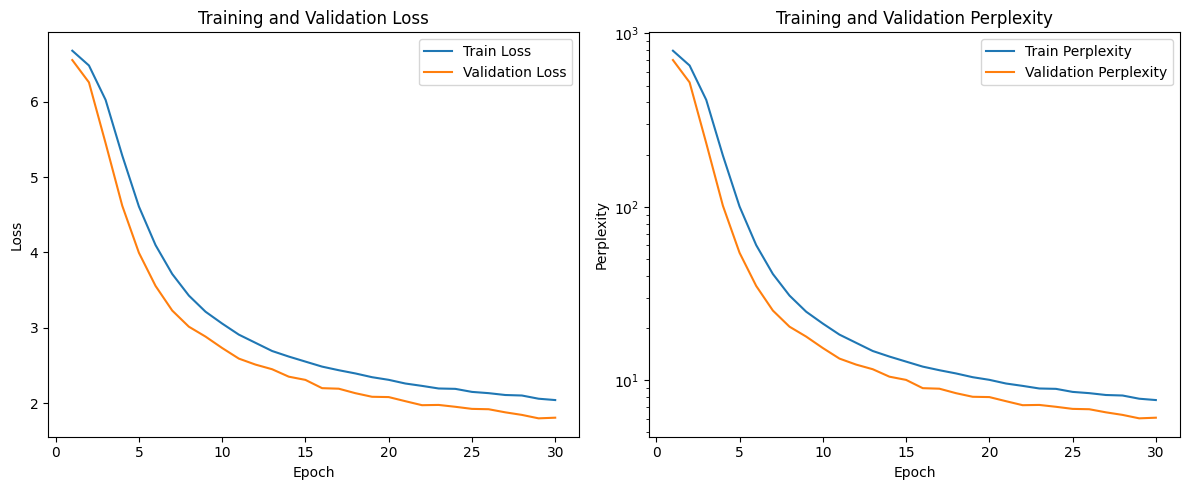

In [54]:
# Calcula perplexidade a partir das losses
train_perplexities = [np.exp(l) for l in train_losses]
val_perplexities = [np.exp(l) for l in val_losses]

# Plot da loss
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(range(1, int(num_epochs) + 1), train_losses, label='Train Loss')
plt.plot(range(1, int(num_epochs) + 1), val_losses, label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
# plt.grid(True)

# Plot da perplexidade
plt.subplot(1, 2, 2)
plt.plot(range(1, int(num_epochs) + 1), train_perplexities, label='Train Perplexity')
plt.plot(range(1, int(num_epochs) + 1), val_perplexities, label='Validation Perplexity')
plt.xlabel('Epoch')
plt.ylabel('Perplexity')
plt.title('Training and Validation Perplexity')
plt.legend()
plt.yscale('log')
# plt.grid(True)

plt.tight_layout()
plt.show()


# Vizz Predictions

In [55]:
def show_model_example(model, dataloader, mask_token_id, id_to_token=None, device=None):
    """
    Mostra um exemplo de entrada real do dataloader, o target esperado e
    a predição do modelo nas posições mascaradas.

    - model: modelo treinado (modo eval será usado)
    - dataloader: DataLoader (ex: val_loader)
    - mask_token_id: ID do token [MASK]
    - id_to_token: dicionário opcional {id: token_str}
    - device: opcional, se None usa device do modelo
    """
    if id_to_token is None:
        id_to_token = {}

    if device is None:
        device = next(model.parameters()).device

    # pega um batch aleatório
    x_batch, y_batch, attn_batch = next(iter(dataloader))
    example_x = x_batch[0]
    example_y = y_batch[0]

    model.eval()
    with torch.no_grad():
        logits = model(example_x.unsqueeze(0).to(device),
                       attention_mask=attn_batch[0].unsqueeze(0).to(device))
        preds = torch.argmax(logits, dim=-1).squeeze(0).cpu()

    # para print legível
    def tok2str(tid):
        return id_to_token.get(tid, str(tid))

    x_ids = example_x.cpu().tolist()
    y_ids = example_y.cpu().tolist()
    p_ids = preds.tolist()

    entrada_str = [tok2str(t) for t in x_ids]
    target_str  = [tok2str(t) if t != -100 else '-' for t in y_ids]
    pred_str    = [tok2str(p) if y_ids[i] != -100 else '-' for i, p in enumerate(p_ids)]

    # prints
    print("\n=== Exemplo de Previsão ===")
    print("Entrada (x):")
    print("[" + " ".join(entrada_str) + "]\n")
    print("Target esperado (y_hat):")
    print("[" + " ".join(target_str) + "]\n")
    print("Predição do modelo (y):")
    print("[" + " ".join(pred_str) + "]\n")

    print(f"{'Posição':<8} {'Token em x':<14} {'Esperado (y)':<20} {'Previsto':<20} {'Correto'}")
    print("-" * 80)

    for i, (xi, yi, pi) in enumerate(zip(x_ids, y_ids, p_ids)):
        if yi == -100:  # não havia target aqui
            continue
        correto = "SIM" if yi == pi else "NÃO"
        print(f"{i:<8} {tok2str(xi):<14} {tok2str(yi):<20} {tok2str(pi):<20} {correto}")

    print("-" * 80)


In [57]:
# Exemplo de uso
show_model_example(model, val_loader, mask_token_id)


=== Exemplo de Previsão ===
Entrada (x):
[700 953 953 953 953 761 760 765 764 954]

Target esperado (y_hat):
[- 681 766 767 763 - - - - -]

Predição do modelo (y):
[- 699 767 763 763 - - - - -]

Posição  Token em x     Esperado (y)         Previsto             Correto
--------------------------------------------------------------------------------
1        953            681                  699                  NÃO
2        953            766                  767                  NÃO
3        953            767                  763                  NÃO
4        953            763                  763                  SIM
--------------------------------------------------------------------------------


## expand logic

In [40]:
# [Célula] EXPAND: insere UMA [MASK] entre cada par consecutivo (bisseção)
def expand_bisect(path_ids, mask_token_id):
    """
    path_ids: lista como [start, ..., goal] (ids individuais)
    retorna: [start, MASK, ..., MASK, goal]
    """
    if len(path_ids) < 2:
        return list(path_ids)

    out = []
    for i in range(len(path_ids) - 1):
        out.append(path_ids[i])
        out.append(mask_token_id)     # exatamente 1 máscara entre cada par
    out.append(path_ids[-1])
    return out


In [41]:
# [Célula] PREDICT: preenche TODAS as [MASK] em uma passada (greedy)
@torch.no_grad()
def predict_masks_once_greedy(model, seq_ids, pad_token_id, mask_token_id):
    """
    seq_ids: sequência com possíveis [MASK].
    retorna: nova sequência com as MASKs substituídas por argmax nos logits.
    Obs.: não passa attention_mask; o modelo já mascara PAD internamente.
    """
    device = next(model.parameters()).device
    x = torch.tensor([seq_ids], dtype=torch.long, device=device)   # [1, T]
    logits = model(x)[0]                                           # [T, V]
    out = list(seq_ids)
    for i, tok in enumerate(seq_ids):
        if tok == mask_token_id:
            out[i] = int(torch.argmax(logits[i]).item())
    return out


In [43]:
# [Célula] Pipeline completo no estilo da figura (bisseção + preenchimento)
def generate_path_bisect_greedy(
    model,
    start_id: int,
    goal_id: int,
    pad_token_id: int,
    mask_token_id: int,
    num_rounds: int = 2,          # igual à figura (duas rodadas)
    id_to_token: None = None,
    print_steps: bool = True,
):
    """
    Inicia com [start, goal]. Em cada rodada:
      expand  -> insere 1 MASK entre cada par (bisseção)
      predict -> preenche todas as MASKs (greedy, uma passada)
    """
    def fmt(seq):
        if id_to_token is None:
            return " ".join(str(int(t)) for t in seq)
        return " ".join(id_to_token.get(int(t), str(int(t))) for t in seq)

    seq = [int(start_id), int(goal_id)]
    logs = [("start", list(seq))]

    if print_steps:
        print("Starting position:", f"[{fmt([start_id])}]")
        print("Goal position:    ", f"[{fmt([goal_id])}]\n")

    for r in range(1, num_rounds + 1):
        # expand (bisseção): [a,b,c] -> [a, MASK, b, MASK, c]
        seq = expand_bisect(seq, mask_token_id)
        logs.append(("expand", list(seq)))
        if print_steps:
            print(f"expand (round {r}):")
            print("[" + fmt(seq) + "]\n")

        # predict (greedy): preenche TODAS as MASKs de uma vez
        seq = predict_masks_once_greedy(model, seq, pad_token_id, mask_token_id)
        logs.append(("predict", list(seq)))
        if print_steps:
            print(f"predict (round {r}):")
            print("[" + fmt(seq) + "]\n")

    return seq, logs


In [58]:
start_id = 760 
goal_id  = 765
seq_final, logs = generate_path_bisect_greedy(
    model,
    start_id=start_id,
    goal_id=goal_id,
    pad_token_id=pad_token_id,
    mask_token_id=mask_token_id,
    num_rounds=2,      # como na figura
    id_to_token=None,  # ou passe o dicionário no futuro
    print_steps=True
)
print("Sequência final (ids):", seq_final)

Starting position: [760]
Goal position:     [765]

expand (round 1):
[760 953 765]

predict (round 1):
[760 767 765]

expand (round 2):
[760 953 767 953 765]

predict (round 2):
[760 765 767 763 765]

Sequência final (ids): [760, 765, 767, 763, 765]


## vizz regions

In [172]:
def plot_position_states_w_title(
    apd: pd.DataFrame,
    grupos_destacados,
    title: str = None,
    cor_outros: str = "#e0e0e0",   # pontos não destacados
    s_outros: int = 10,
    s_destacados: int = 28,
    annotate: bool = True,
    cmap_name: str = "viridis",
):
    """
    Plota os pontos do DataFrame 'apd' (colunas: X, Y, position_state_id),
    destacando 'grupos_destacados' com cores oriundas do colormap viridis,
    respeitando a ordem de aparecimento na lista:

    - ids ANTERIORES: recebem as primeiras cores do colormap, na ordem.
    - id ÚLTIMO: recebe a cor final do colormap (mais destacada).
    - Anotações (labels) sempre em preto.

    Parâmetros:
    - apd: DataFrame com colunas ['X','Y','position_state_id']
    - grupos_destacados: lista ordenada de ids (ordem define a sequência de cores)
    - title: título opcional
    - cor_outros, s_outros: cor e tamanho dos pontos não-destacados
    - s_destacados: tamanho dos pontos destacados
    - annotate: desenhar anotações das médias por grupo
    - cmap_name: nome do colormap (default 'viridis')
    """

    if not {"X", "Y", "position_state_id"}.issubset(apd.columns):
        raise ValueError("apd deve conter as colunas: 'X', 'Y', 'position_state_id'")

    # Remove duplicados preservando a ordem
    ordem_unica = list(dict.fromkeys(grupos_destacados))
    n = len(ordem_unica)

    plt.figure(figsize=(12, 12))

    # 1) Plota todos os pontos não destacados
    destaque_mask = apd["position_state_id"].isin(ordem_unica)
    outros = apd[~destaque_mask]
    if not outros.empty:
        plt.scatter(outros["X"], outros["Y"], color=cor_outros, s=s_outros, label="Outros", zorder=1)

    if n > 0:
        cmap = cm.get_cmap(cmap_name, max(n, 2))

        # Mapeia cores: anteriores = cmap(0..n-2), último = cmap(n-1)
        anteriores_ids = ordem_unica[:-1]
        ultimo_id = ordem_unica[-1]

        # --- Anteriores (na ordem, cada um com sua cor do viridis) ---
        for i, gid in enumerate(anteriores_ids):
            cor_i = cmap(i / (max(n - 1, 1)))  # normaliza 0..1 mesmo quando n-1 = 1
            grp = apd[apd["position_state_id"] == gid]
            if not grp.empty:
                plt.scatter(
                    grp["X"], grp["Y"],
                    color=cor_i, s=s_destacados,
                    label=None if i else "Destacados (anteriores)",
                    zorder=2
                )

        # --- Último (usa a ponta do colormap) ---
        grp_last = apd[apd["position_state_id"] == ultimo_id]
        if not grp_last.empty:
            cor_last = cmap(1.0)  # última cor do viridis
            plt.scatter(
                grp_last["X"], grp_last["Y"],
                color=cor_last, s=s_destacados,
                label="Destacado (último)",
                zorder=3
            )

        # --- Anotações (sempre em preto) ---
        if annotate:
            medias = apd[apd["position_state_id"].isin(ordem_unica)] \
                        .groupby("position_state_id")[["X", "Y"]].mean().reset_index()
            for _, row in medias.iterrows():
                plt.annotate(
                    str(row["position_state_id"]),
                    (row["X"], row["Y"]),
                    fontsize=8, alpha=0.95,
                    ha="center", va="center",
                    fontweight="bold",
                    color="black",  # sempre preto
                    zorder=4
                )

    # Layout
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.title(title if title else "Grupos destacados por position_state_id (viridis por ordem)")
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True, alpha=0.3)
    plt.gca().set_aspect("equal", adjustable="box")

    # Legenda enxuta, se houver algo além de "Outros"
    handles, labels = plt.gca().get_legend_handles_labels()
    if handles:
        # remove duplicatas mantendo ordem
        seen = set()
        uniq_handles, uniq_labels = [], []
        for h, l in zip(handles, labels):
            if l not in seen and l != "":
                uniq_handles.append(h)
                uniq_labels.append(l)
                seen.add(l)
        plt.legend(uniq_handles, uniq_labels, loc="best")

    # Não chama plt.show(); quem usa decide salvar/mostrar


## weigths

In [ ]:
model.encoder.layers[0].self_attn.

MultiheadAttention(
  (out_proj): NonDynamicallyQuantizableLinear(in_features=256, out_features=256, bias=True)
)

In [73]:
@torch.no_grad()
def attention_weight_summaries(model):
    """
    Retorna dicionário com tensores (CPU) dos pesos de atenção por camada:
    - Wq, Wk, Wv, Wout (e biases).
    """
    attn_weights = []  # lista por camada
    # O TransformerEncoder guarda as camadas em model.encoder.layers
    for layer in model.encoder.layers:
        attn = layer.self_attn  # nn.MultiheadAttention
        # in_proj_weight empilha [Wq; Wk; Wv] com shape (3*E, E)
        in_w = attn.in_proj_weight.detach().cpu()            # [3E, E]
        E = in_w.shape[1]
        Wq, Wk, Wv = in_w[:E], in_w[E:2*E], in_w[2*E:3*E]

        in_b = attn.in_proj_bias.detach().cpu() if attn.in_proj_bias is not None else None
        if in_b is not None:
            bq, bk, bv = in_b[:E], in_b[E:2*E], in_b[2*E:3*E]
        else:
            bq = bk = bv = None

        Wout = attn.out_proj.weight.detach().cpu()          # [E, E]
        bout = attn.out_proj.bias.detach().cpu() if attn.out_proj.bias is not None else None

        attn_weights.append({
            "Wq": Wq, "Wk": Wk, "Wv": Wv, "Wout": Wout,
            "bq": bq, "bk": bk, "bv": bv, "bout": bout
        })
    return attn_weights

def plot_layerwise_norms(attn_weights):
    """
    Faz um gráfico de linhas com normas L2 de Wq, Wk, Wv e Wout por camada.
    """
    Wq_norms, Wk_norms, Wv_norms, Wout_norms = [], [], [], []
    for w in attn_weights:
        Wq_norms.append(torch.linalg.norm(w["Wq"]).item())
        Wk_norms.append(torch.linalg.norm(w["Wk"]).item())
        Wv_norms.append(torch.linalg.norm(w["Wv"]).item())
        Wout_norms.append(torch.linalg.norm(w["Wout"]).item())

    layers = list(range(len(attn_weights)))
    plt.figure()
    plt.plot(layers, Wq_norms, marker="o", label="‖Wq‖₂")
    plt.plot(layers, Wk_norms, marker="o", label="‖Wk‖₂")
    plt.plot(layers, Wv_norms, marker="o", label="‖Wv‖₂")
    plt.plot(layers, Wout_norms, marker="o", label="‖Wout‖₂")
    plt.xlabel("Camada do Encoder (0-index)")
    plt.ylabel("Norma L2")
    plt.title("Normas dos pesos de atenção por camada")
    plt.legend()
    plt.tight_layout()
    plt.show()

def plot_weight_histogram(attn_weights, layer_idx=0, which="Wq", bins=80):
    """
    Histograma dos valores dos pesos (Wq/Wk/Wv/Wout) de uma camada.
    """
    w = attn_weights[layer_idx][which].flatten()
    plt.figure()
    plt.hist(w.numpy(), bins=bins)
    plt.xlabel("Valor do peso")
    plt.ylabel("Frequência")
    plt.title(f"Histograma de {which} — Camada {layer_idx}")
    plt.tight_layout()
    plt.show()

def plot_weight_heatmap(attn_weights, layer_idx=0, which="Wq"):
    """
    Heatmap simples (imshow) do peso selecionado (Wq/Wk/Wv/Wout) de uma camada.
    Obs: para matrizes grandes, é só para ter noção de padrão/estruturas.
    """
    w = attn_weights[layer_idx][which]
    plt.figure()
    plt.imshow(w.numpy(), aspect="auto")
    plt.colorbar()
    plt.xlabel("Dimensão de entrada")
    plt.ylabel("Linhas da matriz")
    plt.title(f"Heatmap de {which} — Camada {layer_idx}")
    plt.tight_layout()
    plt.show()


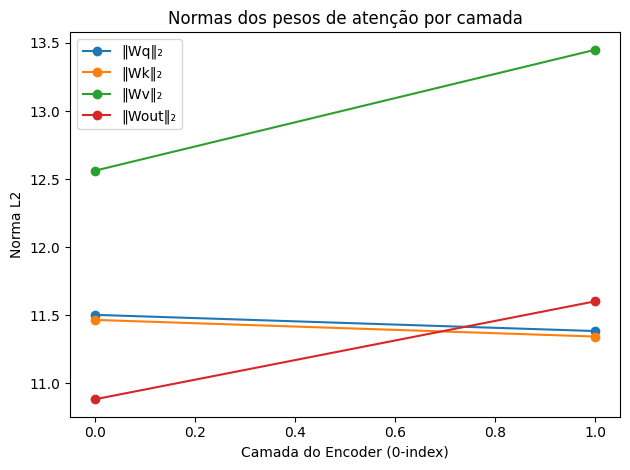

In [74]:
# 1) Coletar pesos de atenção
attn_ws = attention_weight_summaries(model)

# 2) Gráfico de linhas com normas por camada (Q, K, V e out)
plot_layerwise_norms(attn_ws)

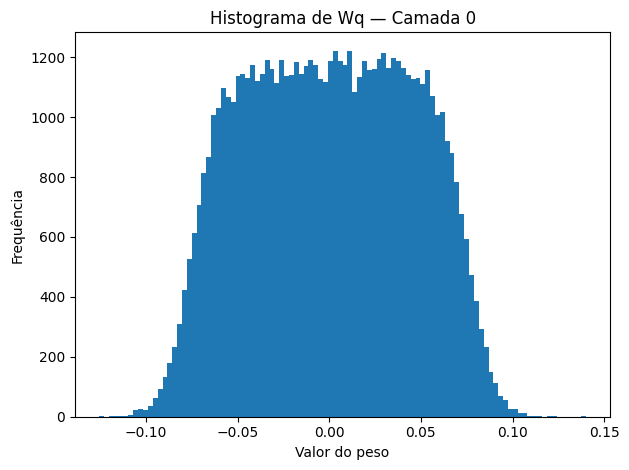

In [75]:
# 3) Histograma dos pesos de Wq da camada 0 (mude o índice/which se quiser)
plot_weight_histogram(attn_ws, layer_idx=0, which="Wq", bins=100)

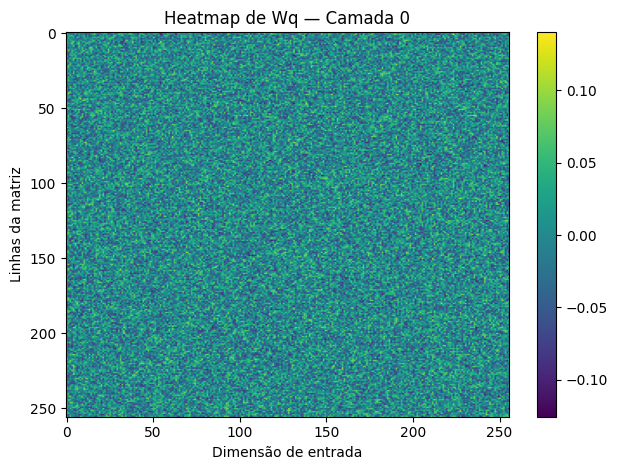

In [76]:

# 4) Heatmap de Wq da camada 0
plot_weight_heatmap(attn_ws, layer_idx=0, which="Wq")

In [ ]:
def plot_position_states_w_title(
    apd: pd.DataFrame,
    grupos_destacados,
    title: str = None,
    cor_outros: str = "#e0e0e0",   # pontos não destacados
    s_outros: int = 10,
    s_destacados: int = 28,
    annotate: bool = True,
    cmap_name: str = "viridis",
):
    """
    Plota os pontos do DataFrame 'apd' (colunas: X, Y, position_state_id),
    destacando 'grupos_destacados' com cores oriundas do colormap viridis,
    respeitando a ordem de aparecimento na lista:

    - ids ANTERIORES: recebem as primeiras cores do colormap, na ordem.
    - id ÚLTIMO: recebe a cor final do colormap (mais destacada).
    - Anotações (labels) sempre em preto.

    Parâmetros:
    - apd: DataFrame com colunas ['X','Y','position_state_id']
    - grupos_destacados: lista ordenada de ids (ordem define a sequência de cores)
    - title: título opcional
    - cor_outros, s_outros: cor e tamanho dos pontos não-destacados
    - s_destacados: tamanho dos pontos destacados
    - annotate: desenhar anotações das médias por grupo
    - cmap_name: nome do colormap (default 'viridis')
    """

    if not {"X", "Y", "position_state_id"}.issubset(apd.columns):
        raise ValueError("apd deve conter as colunas: 'X', 'Y', 'position_state_id'")

    # Remove duplicados preservando a ordem
    ordem_unica = list(dict.fromkeys(grupos_destacados))
    n = len(ordem_unica)

    plt.figure(figsize=(12, 12))

    # 1) Plota todos os pontos não destacados
    destaque_mask = apd["position_state_id"].isin(ordem_unica)
    outros = apd[~destaque_mask]
    if not outros.empty:
        plt.scatter(outros["X"], outros["Y"], color=cor_outros, s=s_outros, label="Outros", zorder=1)

    if n > 0:
        cmap = cm.get_cmap(cmap_name, max(n, 2))

        # Mapeia cores: anteriores = cmap(0..n-2), último = cmap(n-1)
        anteriores_ids = ordem_unica[:-1]
        ultimo_id = ordem_unica[-1]

        # --- Anteriores (na ordem, cada um com sua cor do viridis) ---
        for i, gid in enumerate(anteriores_ids):
            cor_i = cmap(i / (max(n - 1, 1)))  # normaliza 0..1 mesmo quando n-1 = 1
            grp = apd[apd["position_state_id"] == gid]
            if not grp.empty:
                plt.scatter(
                    grp["X"], grp["Y"],
                    color=cor_i, s=s_destacados,
                    label=None if i else "Destacados (anteriores)",
                    zorder=2
                )

        # --- Último (usa a ponta do colormap) ---
        grp_last = apd[apd["position_state_id"] == ultimo_id]
        if not grp_last.empty:
            cor_last = cmap(1.0)  # última cor do viridis
            plt.scatter(
                grp_last["X"], grp_last["Y"],
                color=cor_last, s=s_destacados,
                label="Destacado (último)",
                zorder=3
            )

        # --- Anotações (sempre em preto) ---
        if annotate:
            medias = apd[apd["position_state_id"].isin(ordem_unica)] \
                        .groupby("position_state_id")[["X", "Y"]].mean().reset_index()
            for _, row in medias.iterrows():
                plt.annotate(
                    str(row["position_state_id"]),
                    (row["X"], row["Y"]),
                    fontsize=8, alpha=0.95,
                    ha="center", va="center",
                    fontweight="bold",
                    color="black",  # sempre preto
                    zorder=4
                )

    # Layout
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.title(title if title else "Grupos destacados por position_state_id (viridis por ordem)")
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True, alpha=0.3)
    plt.gca().set_aspect("equal", adjustable="box")

    # Legenda enxuta, se houver algo além de "Outros"
    handles, labels = plt.gca().get_legend_handles_labels()
    if handles:
        # remove duplicatas mantendo ordem
        seen = set()
        uniq_handles, uniq_labels = [], []
        for h, l in zip(handles, labels):
            if l not in seen and l != "":
                uniq_handles.append(h)
                uniq_labels.append(l)
                seen.add(l)
        plt.legend(uniq_handles, uniq_labels, loc="best")

    # Não chama plt.show(); quem usa decide salvar/mostrar


In [81]:
def gerar_graficos_expansao(apd, sequencias_ids, pasta_destino="imgs", titulo_base="Passo", dpi=150):
    """
    Gera e salva gráficos por etapas, pintando as regiões em função da lista de ids recebida.
    NÃO executa modelo; apenas plota conforme as sequências fornecidas.

    Parâmetros:
    - apd: DataFrame com colunas ['X','Y','position_state_id']
    - sequencias_ids: lista de listas de ids (ex.: [[s,e], [s,x,e], [s,x,y,e], ...])
                      Cada sublista é um "passo" do GIF.
    - pasta_destino: pasta onde os PNGs serão salvos
    - titulo_base: prefixo do título (ex.: "Passo")
    - dpi: resolução dos PNGs

    Retorna:
    - lista com os caminhos dos arquivos gerados
    """
    if not isinstance(sequencias_ids, (list, tuple)) or len(sequencias_ids) == 0:
        raise ValueError("sequencias_ids deve ser uma lista não vazia de listas de ids.")

    os.makedirs(pasta_destino, exist_ok=True)
    caminhos = []

    for step, ids in enumerate(sequencias_ids):
        if not isinstance(ids, (list, tuple)) or len(ids) == 0:
            raise ValueError(f"Item na posição {step} de sequencias_ids não é uma lista/tupla válida de ids.")

        caminho_arquivo = os.path.join(pasta_destino, f"etapa_{step:02}.png")

        # usa a função definida antes no chat (com viridis, ordem por ids,
        # último em destaque, anotações pretas)
        title = f"{titulo_base} {step:02} | {ids[0]}->{ids[-1]}" if len(ids) >= 2 else f"{titulo_base} {step:02}"
        plot_position_states_w_title(apd, grupos_destacados=list(ids), title=title)

        plt.savefig(caminho_arquivo, bbox_inches="tight", dpi=dpi)
        plt.close()
        caminhos.append(caminho_arquivo)

    return caminhos


In [32]:
def expand_trajectory(model, start_token, end_token, mask_token_id, max_len=12, id_to_token=None):
    """
    Expande uma sequência entre start_token e end_token, preenchendo iterativamente
    tokens intermediários e mostrando o histórico de predições.
    """
    device = next(model.parameters()).device
    sequence = [start_token, end_token]
    step = 1

    while len(sequence) < max_len:
        print(f"\n=== Etapa {step} ===")
        print("Sequência atual:", [id_to_token.get(t, str(t)) if id_to_token else t for t in sequence])

        # Inserção de MASKs entre os pares
        new_sequence = []
        for i in range(len(sequence) - 1):
            new_sequence.append(sequence[i])
            new_sequence.append(mask_token_id)
        new_sequence.append(sequence[-1])
        sequence = new_sequence

        print("Com [MASK]:     ", [id_to_token.get(t, str(t)) if id_to_token else t for t in sequence])

        # Predição
        input_tensor = torch.tensor(sequence, dtype=torch.long).unsqueeze(0).to(device)
        with torch.no_grad():
            logits = model(input_tensor)
            predictions = torch.argmax(logits, dim=-1).squeeze(0).cpu().tolist()
            print('Predição Completa', predictions)

        # Substituição dos MASKs e exibição
        updated_sequence = []
        for i, token in enumerate(sequence):
            if token == mask_token_id:
                predicted_token = predictions[i]
                updated_sequence.append(predicted_token)
                print(f"Predição na posição {i}: {id_to_token.get(predicted_token, predicted_token) if id_to_token else predicted_token}")
            else:
                updated_sequence.append(token)

        sequence = updated_sequence
        print("Após predição: ", [id_to_token.get(t, str(t)) if id_to_token else t for t in sequence])

        if len(sequence) >= max_len:
            print("\nLimite de comprimento atingido.")
            break

        step += 1

    print("\n=== Trajetória Final ===")
    print([id_to_token.get(t, str(t)) if id_to_token else t for t in sequence])
    return sequence


In [33]:
np.random.choice(sequences, 2)

array([507, 715])

In [34]:
start_token = 507
end_token = 715
# max_len = 15

In [35]:
expand_trajectory(
    model,
    start_token=start_token,
    end_token=end_token,
    mask_token_id=mask_token_id,
    # max_len=max_len,
    # id_to_token=id_to_token  # ou None
)


=== Etapa 1 ===
Sequência atual: [507, 715]
Com [MASK]:      [507, 953, 715]
Predição Completa [799, 501, 582]
Predição na posição 1: 501
Após predição:  [507, 501, 715]

=== Etapa 2 ===
Sequência atual: [507, 501, 715]
Com [MASK]:      [507, 953, 501, 953, 715]
Predição Completa [332, 583, 583, 340, 716]
Predição na posição 1: 583
Predição na posição 3: 340
Após predição:  [507, 583, 501, 340, 715]

=== Etapa 3 ===
Sequência atual: [507, 583, 501, 340, 715]
Com [MASK]:      [507, 953, 583, 953, 501, 953, 340, 953, 715]
Predição Completa [507, 501, 507, 507, 507, 507, 507, 501, 330]
Predição na posição 1: 501
Predição na posição 3: 507
Predição na posição 5: 507
Predição na posição 7: 501
Após predição:  [507, 501, 583, 507, 501, 507, 340, 501, 715]

=== Etapa 4 ===
Sequência atual: [507, 501, 583, 507, 501, 507, 340, 501, 715]
Com [MASK]:      [507, 953, 501, 953, 583, 953, 507, 953, 501, 953, 507, 953, 340, 953, 501, 953, 715]
Predição Completa [507, 583, 340, 507, 507, 501, 507, 34

[507,
 583,
 501,
 507,
 583,
 501,
 507,
 340,
 501,
 507,
 507,
 501,
 340,
 507,
 501,
 501,
 715]

In [173]:
apd = pd.read_parquet(r'apd_full.gzip')
apd.shape

: 

In [43]:
df_ps_to_apd_id = {ps:idx for ps, idx in zip(df['position_state'], df['position_state_id'])}

In [46]:
df['position_state_id'].max()

953

In [48]:
count = 0
current_max_id = df['position_state_id'].max() + 1
for apd_ps in apd['position_state'].unique():
    if apd_ps not in df_ps_to_apd_id:
        df_ps_to_apd_id[apd_ps]  = current_max_id
        current_max_id+=1
        count+=1
print(count)

0


In [50]:
apd['position_state_id'] = [df_ps_to_apd_id[ps] for ps in apd['position_state']]

In [55]:
apd['position_state_id'].nunique()

1057

In [86]:
x_batch, y_batch = next(iter(val_loader))
example_x = x_batch[0]
example_y = y_batch[0]

visualize_predictions(model, example_x, example_y, mask_token_id)


Entrada (x):
[503 953 570 953 598 954 954 954 954 954 954 954 954 954 954]

Target (y_hat):
[- 504 - 568 - - - - - - - - - - -]


Predição (y):
[511 504 499 511 511 564 564 564 564 564 564 564 564 564 564]

Posição  Token em x     Esperado (y)         Previsto             Correto
--------------------------------------------------------------------------------
1        953            504                  504                  SIM
3        953            568                  511                  NÃO
--------------------------------------------------------------------------------


/tmp/ipykernel_1050/2161532076.py:50: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap(cmap_name, max(n, 2))


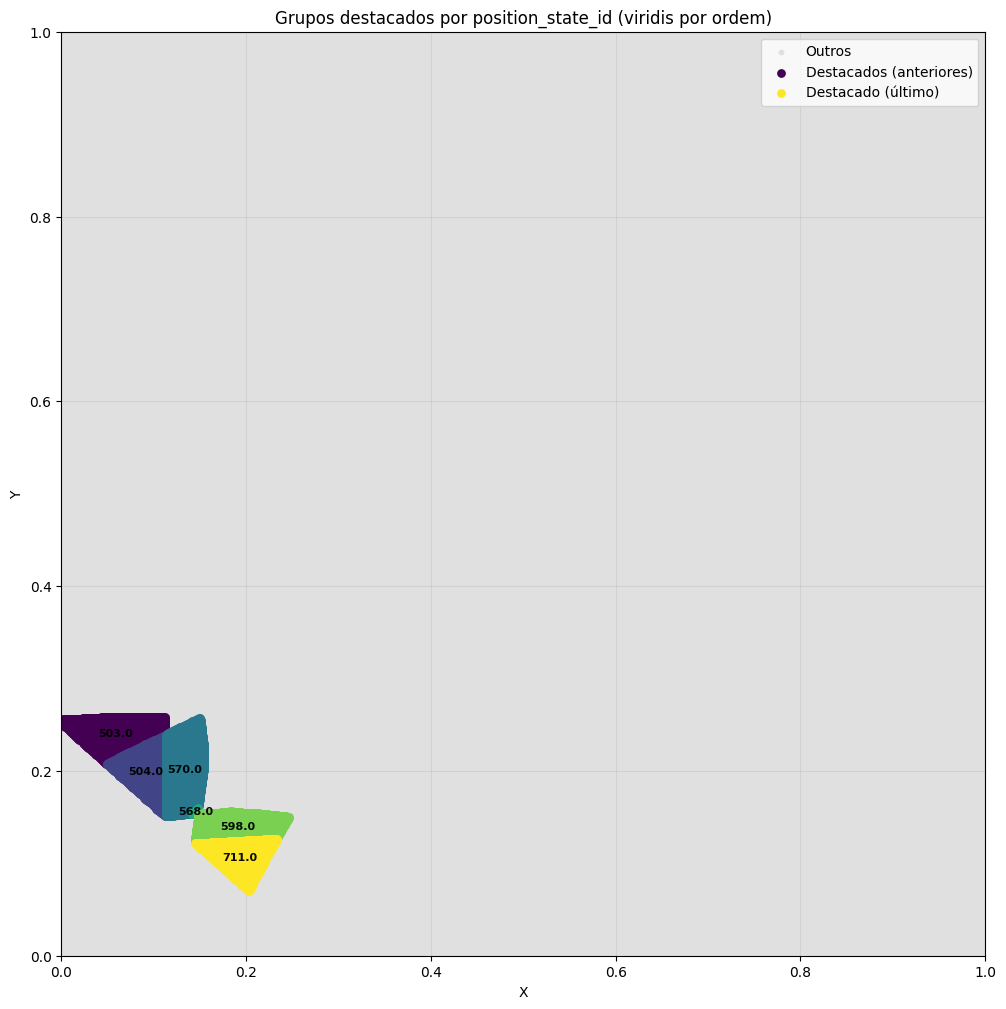

In [85]:
plot_position_states_w_title(apd, [503, 504, 570, 568, 598, 711])

In [ ]:
def plot_position_states(apd, grupos_destacados):
    """
    Plota os pontos do DataFrame apd (com colunas X, Y e position_state_id),
    destacando apenas os grupos na lista grupos_destacados, com anotações.

    Parâmetros:
    - apd: DataFrame com colunas 'X', 'Y' e 'position_state_id'
    - grupos_destacados: lista de valores de position_state_id a serem coloridos e anotados
    """
    # Criação da máscara de seleção
    destaque_mask = apd['position_state_id'].isin(grupos_destacados)

    # Define cores: branco ou cinza claro para os pontos não destacados
    cor_base = '#e0e0e0'
    
    plt.figure(figsize=(12, 12))

    # Plota todos os pontos em cinza claro
    plt.scatter(apd['X'], apd['Y'], color=cor_base, s=10, label='Outros')

    # Plota apenas os pontos destacados com colormap
    destacados = apd[destaque_mask]
    if not destacados.empty:
        scatter = plt.scatter(destacados['X'], destacados['Y'],
                              c=destacados['position_state_id'], cmap='tab10', s=25, label='Destacados')

        # Anotar a média dos grupos destacados
        medias = destacados.groupby('position_state_id')[['X', 'Y']].mean().reset_index()
        for _, row in medias.iterrows():
            plt.annotate(str(row['position_state_id']), (row['X'], row['Y']),
                         fontsize=7, alpha=0.9, ha='center', va='center', fontweight='bold')

        # Adiciona colorbar apenas se houver grupos destacados
        cbar = plt.colorbar(scatter)
        cbar.set_label('position_state_id destacado')

    # Layout
    plt.xlabel('X')
    plt.ylabel('Y')
    plt.title('Grupos destacados por position_state_id')
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True)
    plt.gca().set_aspect('equal', adjustable='box')
    plt.legend()
    plt.show()

In [ ]:
def plot_position_states_w_region(apd, region):
    """
    Plota os pontos do DataFrame apd, destacando grupos (position_state_id)
    que possuem pontos dentro da região [xmin, xmax, ymin, ymax].

    Parâmetros:
    - apd: DataFrame com colunas 'X', 'Y', 'position_state_id'
    - region: lista ou tupla com [xmin, xmax, ymin, ymax]
    """
    xmin, xmax, ymin, ymax = region

    # Filtrar os pontos que estão dentro da região
    dentro = apd[(apd['X'] >= xmin) & (apd['X'] <= xmax) &
                 (apd['Y'] >= ymin) & (apd['Y'] <= ymax)]

    # Identificar os grupos que têm pelo menos um ponto na região
    grupos_destacados = dentro['position_state_id'].unique()
    print('Grupos Destados', grupos_destacados)

    # Máscara dos grupos destacados
    destaque_mask = apd['position_state_id'].isin(grupos_destacados)

    # Plot
    plt.figure(figsize=(12, 12))

    # Pontos não destacados (fundo)
    cor_base = '#e0e0e0'
    plt.scatter(apd['X'], apd['Y'], color=cor_base, s=10, label='Outros')

    # Pontos destacados (na região)
    destacados = apd[destaque_mask]
    if not destacados.empty:
        scatter = plt.scatter(destacados['X'], destacados['Y'],
                              c=destacados['position_state_id'], cmap='tab10', s=25, label='Destacados')

        # Anotar centro de massa de cada grupo destacado
        medias = destacados.groupby('position_state_id')[['X', 'Y']].mean().reset_index()
        for _, row in medias.iterrows():
            plt.annotate(str(row['position_state_id']), (row['X'], row['Y']),
                         fontsize=7, alpha=0.9, ha='center', va='center', fontweight='bold')

        # Colorbar
        cbar = plt.colorbar(scatter)
        cbar.set_label('position_state_id destacado')

    # Desenhar a região no gráfico
    plt.plot([xmin, xmax, xmax, xmin, xmin],
             [ymin, ymin, ymax, ymax, ymin], color='black', linestyle='--', linewidth=1.2, label='Região')

    # Layout
    plt.xlabel('X')
    plt.ylabel('Y')
    plt.title('Grupos destacados por interseção com região')
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True)
    plt.gca().set_aspect('equal', adjustable='box')
    plt.legend()
    plt.show()

Grupos Destados [891 892 902 899]


/home/mgteus/workspace/navitrans/.nav/lib/python3.8/site-packages/IPython/core/pylabtools.py:152: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


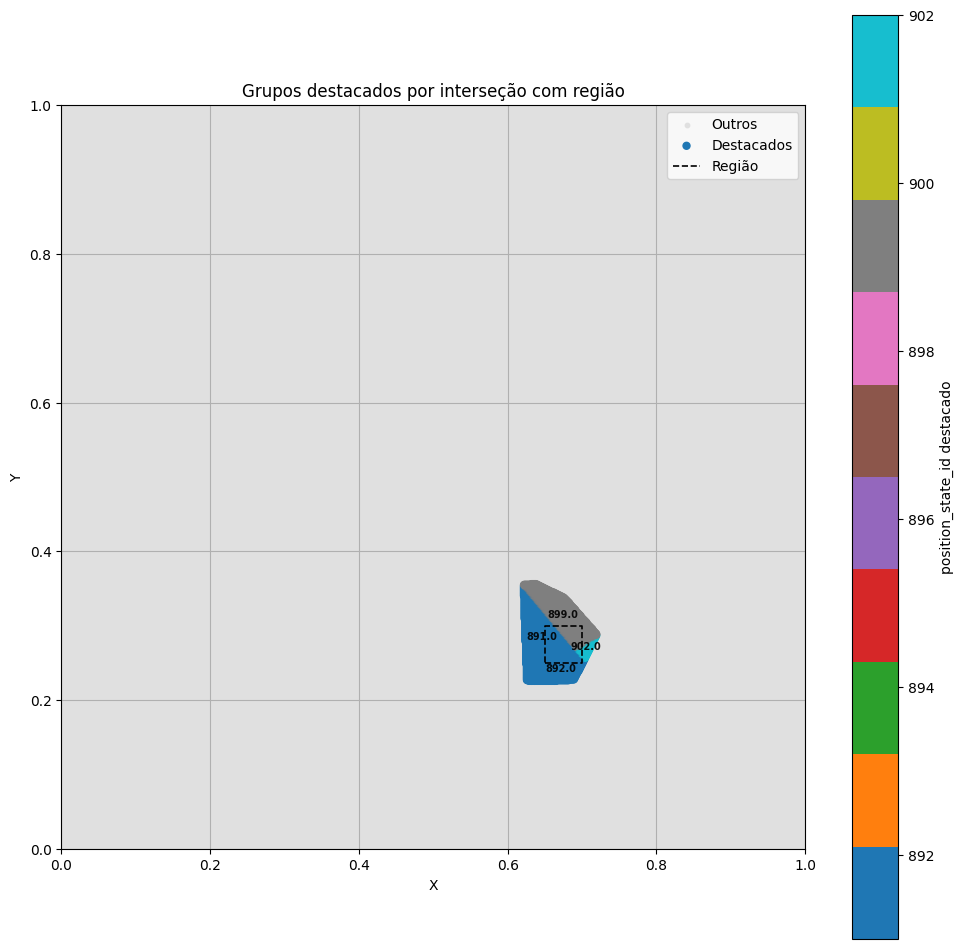

In [56]:
plot_position_states_w_region(apd, region=[0.65, 0.7, 0.25, 0.3])

/home/mgteus/workspace/navitrans/.nav/lib/python3.8/site-packages/IPython/core/pylabtools.py:152: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


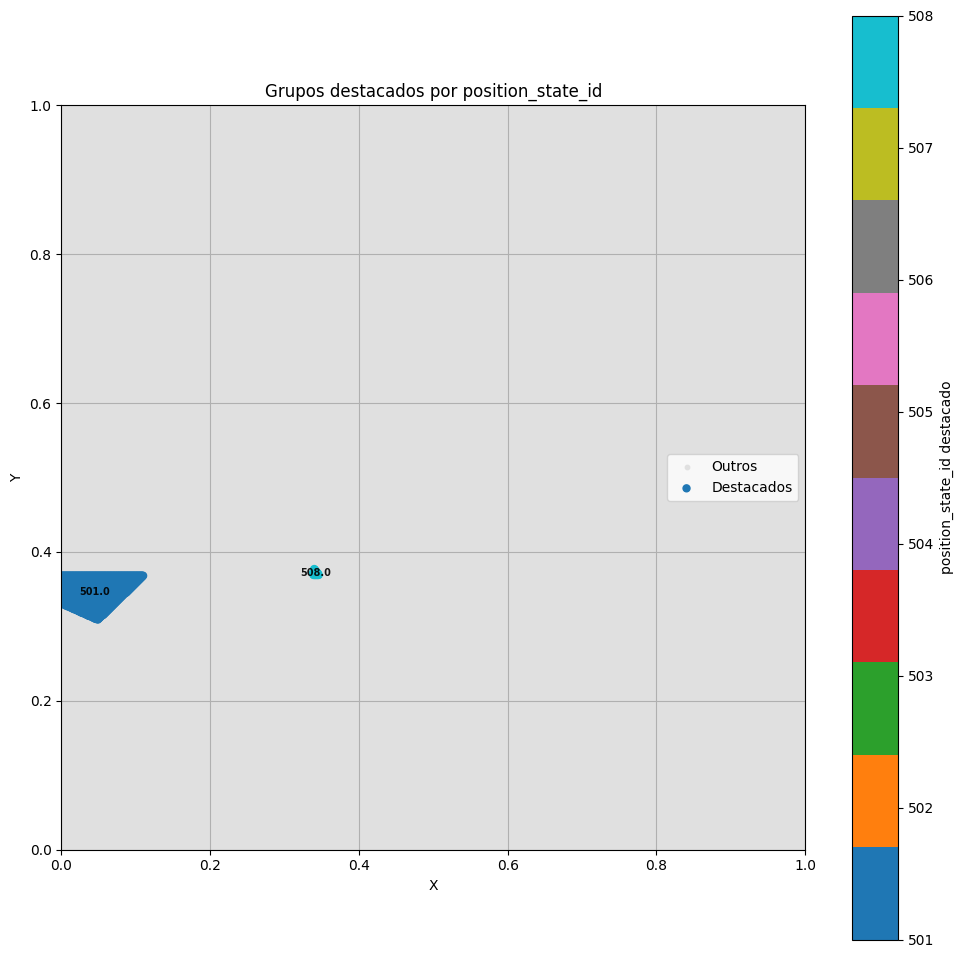

In [54]:
plot_position_states(apd, [501, 508])

/tmp/ipykernel_1050/2161532076.py:50: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap(cmap_name, max(n, 2))


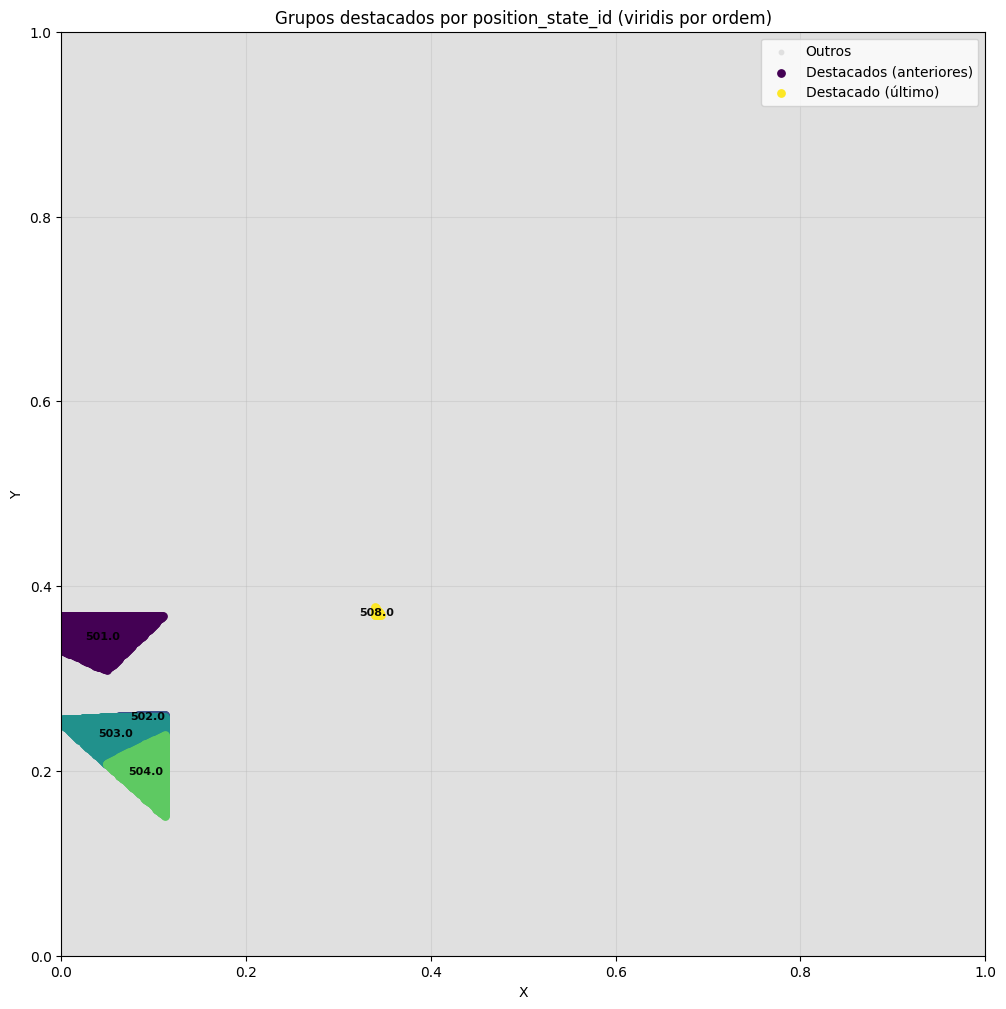

In [72]:
plot_position_states_w_title(apd, [501,502, 503, 504, 508])

In [63]:
def gerar_graficos_expansao(model, start_token, end_token, mask_token_id,
                             max_len,  apd, pasta_destino="imgs"):
    """
    Executa a expansão da trajetória e salva os gráficos das etapas destacando os grupos preditos.

    Parâmetros:
    - model: modelo de linguagem
    - start_token, end_token, mask_token_id, pad_token_id: tokens especiais
    - max_len: tamanho máximo da sequência
    - id_to_token: dicionário de id para string
    - apd: DataFrame com colunas 'X', 'Y', 'position_state_id'
    - pasta_destino: pasta onde os gráficos serão salvos
    """
    os.makedirs(pasta_destino, exist_ok=True)
    step = 0
    # Salva gráfico com os novos IDs destacados
    caminho_arquivo = os.path.join(pasta_destino, f"etapa_{step:02}.png")
    device = next(model.parameters()).device
    sequence = [start_token, end_token]
    plot_position_states_w_title(apd, grupos_destacados=sequence, title=f"Passo {step:02} | {sequence[0]}->{sequence[1]}")
    plt.savefig(caminho_arquivo)
    plt.close()
    step +=1
    

    while len(sequence) < max_len:
        # Inserir [MASK] entre os pares
        new_sequence = []
        for i in range(len(sequence) - 1):
            new_sequence.append(sequence[i])
            new_sequence.append(mask_token_id)
        new_sequence.append(sequence[-1])
        sequence = new_sequence

        # Predição
        input_tensor = torch.tensor(sequence, dtype=torch.long).unsqueeze(0).to(device)
        with torch.no_grad():
            logits = model(input_tensor)
            predictions = torch.argmax(logits, dim=-1).squeeze(0).cpu().tolist()

        # Substituição dos MASKs
        updated_sequence = []
        novos_ids = []
        for i, token in enumerate(sequence):
            if token == mask_token_id:
                predicted_token = predictions[i]
                updated_sequence.append(predicted_token)
                novos_ids.append(predicted_token)
            else:
                updated_sequence.append(token)

        sequence = updated_sequence
        print(sequence)
        
        # print(novos_ids)
        caminho_arquivo = os.path.join(pasta_destino, f"etapa_{step:02}.png")
        plot_position_states_w_title(apd, grupos_destacados=updated_sequence, title=f"Passo {step:02}")
        plt.savefig(caminho_arquivo)
        plt.close()

        if len(sequence) >= max_len:
            break
        step += 1

    return


In [64]:
start_token = 501
end_token = 508
max_len = 20

In [73]:
gerar_graficos_expansao(
    model,
    start_token=start_token,
    end_token=end_token,
    mask_token_id=mask_token_id,
    max_len=max_len,
    apd=apd
)

/tmp/ipykernel_1050/2161532076.py:50: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap(cmap_name, max(n, 2))


[501, 507, 508]


/tmp/ipykernel_1050/2161532076.py:50: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap(cmap_name, max(n, 2))


[501, 583, 507, 501, 508]


/tmp/ipykernel_1050/2161532076.py:50: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap(cmap_name, max(n, 2))


...

/tmp/ipykernel_1050/2161532076.py:50: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap(cmap_name, max(n, 2))


[501, 583, 507, 501, 583, 507, 501, 583, 507, 583, 505, 507, 501, 507, 500, 340, 508]


/tmp/ipykernel_1050/2161532076.py:50: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap(cmap_name, max(n, 2))


[501, 507, 583, 501, 507, 505, 501, 507, 583, 507, 507, 340, 501, 507, 583, 501, 507, 507, 583, 501, 505, 501, 507, 501, 501, 501, 507, 501, 500, 505, 340, 507, 508]


/tmp/ipykernel_1050/2161532076.py:50: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap(cmap_name, max(n, 2))


In [60]:
def gerar_gif(pasta_imagens, nome_gif='trajetoria_animada.gif', duracao=1000):
    """
    Gera um GIF animado com os gráficos salvos.

    Parâmetros:
    - pasta_imagens: pasta onde estão os arquivos PNG
    - nome_gif: nome do arquivo de saída
    - duracao: duração entre os frames (em ms)
    """
    arquivos = sorted(glob.glob(os.path.join(pasta_imagens, "*.png")))
    imagens = [Image.open(arquivo) for arquivo in arquivos]

    if imagens:
        imagens[0].save(nome_gif, save_all=True, append_images=imagens[1:], duration=duracao, loop=0)
        print(f"GIF salvo como {nome_gif}")
    else:
        print("Nenhuma imagem encontrada para criar o GIF.")

In [61]:
# filepaths
fp_in = r"imgs/*.png"
fp_out = "gif_s25.gif"

# # # https://pillow.readthedocs.io/en/stable/handbook/image-file-formats.html#gif
img, *imgs = [Image.open(f) for f in sorted(glob.glob(fp_in))]
img.save(fp=fp_out, format='GIF', append_images=imgs,
         save_all=True, duration=500, loop=0)   

In [59]:
for i in sorted(glob.glob(fp_in)):
    print(i)

imgs/etapa_00.png
imgs/etapa_01.png
imgs/etapa_02.png
imgs/etapa_03.png
imgs/etapa_04.png


In [54]:
gerar_gif('imgs/', )

GIF salvo como trajetoria_animada.gif
